# Velora Brewing - Exploratory Data Analysis (EDA)
**Week 4 deliverable: Manufacturing and sales EDA report**

**What is EDA?** Looking at the data with tables and charts *before* modelling, to learn what is normal, what is unusual, and what is broken.

**How to use this notebook:** run the cells from top to bottom with **Shift+Enter**. Each section has three parts: the **question**, a **chart**, and the **finding**.

**Rules we follow**
- Revenue and profit figures **exclude cancelled orders**.
- 2026 contains data only up to **31 October**, so we compare the *same months* across years.
- All data is **synthetic**: findings describe this dataset, not a real brewery.

In [1]:
import sys
print(sys.executable)

C:\Users\yaswa\Desktop\velora-brewing-analytics\velora-brewing-analytics\venv\Scripts\python.exe


In [1]:
import os, sys
from pathlib import Path

PROJECT = None   # Only if the next lines fail: put your project path here, e.g. r"C:\Users\you\velora-brewing-analytics"
start = Path(PROJECT) if PROJECT else Path.cwd()
for folder in [start, *start.parents]:
    if (folder / "src" / "load_data.py").exists():
        os.chdir(folder)
        break
else:
    raise FileNotFoundError("Project folder not found. Set PROJECT above to your project folder path.")
sys.path.append("src")
print("Working folder:", Path.cwd())

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from load_data import load_data_tables

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 12})
BLUE, ORANGE, GREY = "#2E6F95", "#E07A5F", "#9AA5B1"
FIG_DIR = Path("reports/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

Working folder: /home/claude/velora-brewing-analytics


## 1. Load and prepare the data
We load all tables, add readable product names, and build the **`sales`** table: order lines of orders that were *not* cancelled.

In [2]:
tables = load_data_tables()
pm = tables["Product_Master"].set_index("product_id")

# --- Manufacturing ---
batches = tables["Production_Batches"].copy()
batches["product"] = batches["product_id"].map(pm["product_name"])
batches["target_yield"] = batches["product_id"].map(pm["target_yield_rate"])
batches["yield_pct"] = batches["yield_rate"] * 100
batches["line"] = batches["production_line"].str.replace("Maribor ", "", regex=False)
batches["month"] = batches["production_date"].dt.to_period("M").dt.to_timestamp()
batches["year"] = batches["production_date"].dt.year

qc = tables["Quality_Control"].merge(batches[["batch_id", "product", "line"]], on="batch_id")
qc["is_review"] = (qc["quality_status"] == "Review")

# --- Sales ---
orders = tables["Sales_Orders"].copy()
lines = tables["Sales_Order_Lines"].merge(orders, on="order_id")
lines["product"] = lines["product_id"].map(pm["product_name"])
sales = lines[lines["order_status"] != "Cancelled"].copy()
sales["year"] = sales["order_date"].dt.year
sales["month_no"] = sales["order_date"].dt.month
sales["month"] = sales["order_date"].dt.to_period("M").dt.to_timestamp()

print(f"Batches: {len(batches)} | QC tests: {len(qc)} | Orders: {len(orders)} "
      f"| Order lines (all): {len(lines)} | Order lines (not cancelled): {len(sales)}")

Batches: 465 | QC tests: 465 | Orders: 4500 | Order lines (all): 11278 | Order lines (not cancelled): 9328


## 2. Manufacturing
### 2.1 How much of the planned beer do we actually get? (yield)
**Question:** What is a typical batch yield, and do production lines or batch status change it?
**How to read:** left = how yields are spread; middle and right = the middle line of each box is the median, the box holds the middle 50% of batches.

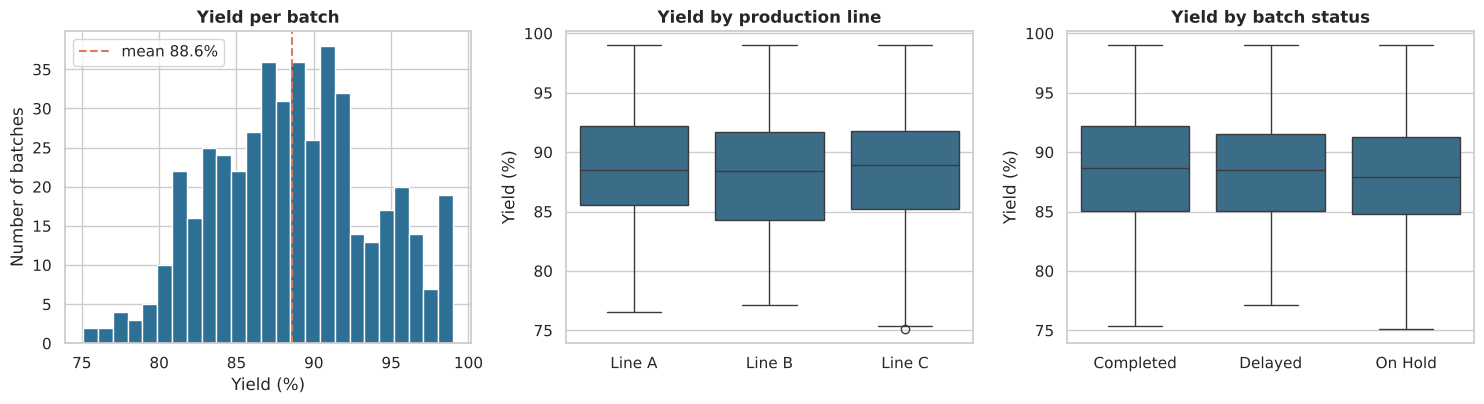

        count   mean   std
line                      
Line A    135  88.95  5.11
Line B    157  88.37  5.12
Line C    173  88.53  5.21

Share of batches below 80% yield: 3.9%
Total planned: 929,024 L | total loss: 105,300 L (11.3%)


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].hist(batches["yield_pct"], bins=25, color=BLUE, edgecolor="white")
ax[0].axvline(batches["yield_pct"].mean(), color=ORANGE, ls="--", label=f"mean {batches['yield_pct'].mean():.1f}%")
ax[0].set(title="Yield per batch", xlabel="Yield (%)", ylabel="Number of batches"); ax[0].legend()
sns.boxplot(data=batches, x="line", y="yield_pct", color=BLUE, ax=ax[1], order=["Line A", "Line B", "Line C"])
ax[1].set(title="Yield by production line", xlabel="", ylabel="Yield (%)")
sns.boxplot(data=batches, x="batch_status", y="yield_pct", color=BLUE, ax=ax[2], order=["Completed", "Delayed", "On Hold"])
ax[2].set(title="Yield by batch status", xlabel="", ylabel="Yield (%)")
save(fig, "fig01_yield_distribution")

print(batches.groupby("line")["yield_pct"].agg(["count", "mean", "std"]).round(2))
print(f"\nShare of batches below 80% yield: {(batches['yield_pct'] < 80).mean():.1%}")
print(f"Total planned: {batches['planned_volume_litre'].sum():,} L | total loss: {batches['production_loss_litre'].sum():,} L "
      f"({batches['production_loss_litre'].sum() / batches['planned_volume_litre'].sum():.1%})")

**Finding.** Yield is centred at **88.6%** (batches range from 75.1% to 99.0%) and only 3.9% of batches fall below 80%. The three lines are almost identical (88.4% to 89.0%), and batch status makes no difference either. A quick ANOVA test gives p = 0.62, so there is no evidence of a line effect. In total 105,300 L of 929,024 L planned were lost (11.3%).

### 2.2 Does each beer reach its target yield?
**Question:** Product_Master gives each beer a `target_yield_rate`. How close is the real average?
**How to read:** blue dot = actual average, orange diamond = target. A short line means actual is close to target.

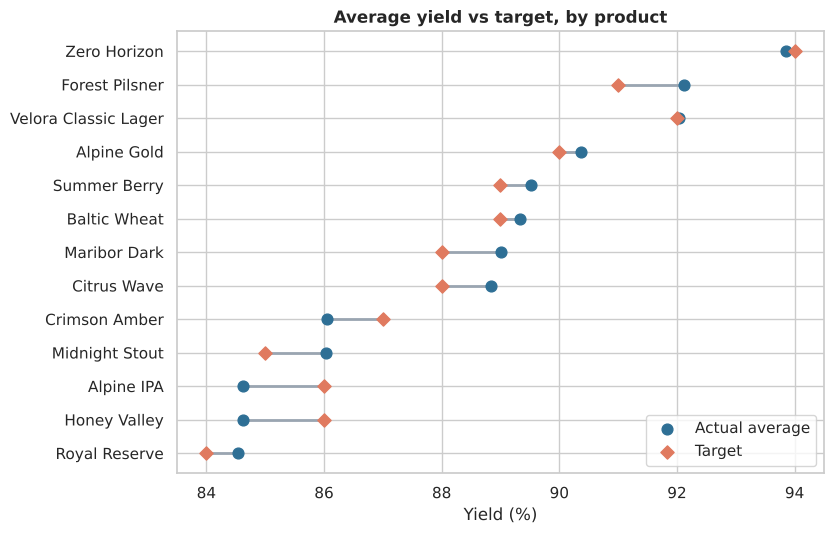

                      actual  target  batches   gap
product                                            
Honey Valley           84.62    86.0       37 -1.38
Alpine IPA             84.62    86.0       31 -1.38
Crimson Amber          86.05    87.0       38 -0.95
Zero Horizon           93.85    94.0       39 -0.15
Velora Classic Lager   92.04    92.0       23  0.04
Baltic Wheat           89.33    89.0       34  0.33
Alpine Gold            90.36    90.0       38  0.36
Summer Berry           89.52    89.0       46  0.52
Royal Reserve          84.55    84.0       26  0.55
Citrus Wave            88.84    88.0       38  0.84
Maribor Dark           89.02    88.0       45  1.02
Midnight Stout         86.04    85.0       36  1.04
Forest Pilsner         92.11    91.0       34  1.11

Batches at or above their own target: 52.9%


In [4]:
g = batches.groupby("product").agg(actual=("yield_rate", "mean"), target=("target_yield", "first"), batches=("batch_id", "count")) * [100, 100, 1]
g["gap"] = g["actual"] - g["target"]
g = g.sort_values("actual")
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.hlines(g.index, g["target"], g["actual"], color=GREY, lw=2)
ax.scatter(g["actual"], g.index, color=BLUE, s=60, zorder=3, label="Actual average")
ax.scatter(g["target"], g.index, color=ORANGE, marker="D", s=45, zorder=3, label="Target")
ax.set(title="Average yield vs target, by product", xlabel="Yield (%)"); ax.legend(loc="lower right")
save(fig, "fig02_yield_vs_target")
print(g.round(2).sort_values("gap"))
print(f"\nBatches at or above their own target: {(batches['yield_rate'] >= batches['target_yield']).mean():.1%}")

**Finding.** Every product averages within **±1.4 points** of its target. Alpine IPA and Honey Valley are furthest below (-1.4 points); Forest Pilsner, Midnight Stout and Maribor Dark are furthest above (+1.0 to +1.1). The beers with the lowest yields (Royal Reserve, Alpine IPA and Honey Valley, all about 84.6%) are simply the beers with the lowest targets. About 53% of batches reach their own target.

### 2.3 Is production loss changing over time? Is yield related to anything else?
**How to read:** the heatmap shows correlation: +1 means two measures rise together, 0 means no link, -1 means one rises when the other falls.

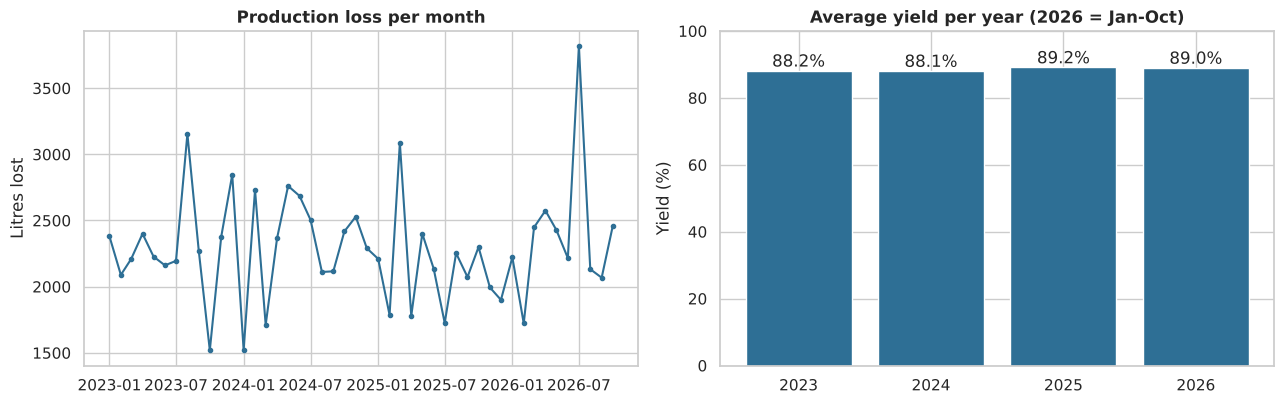

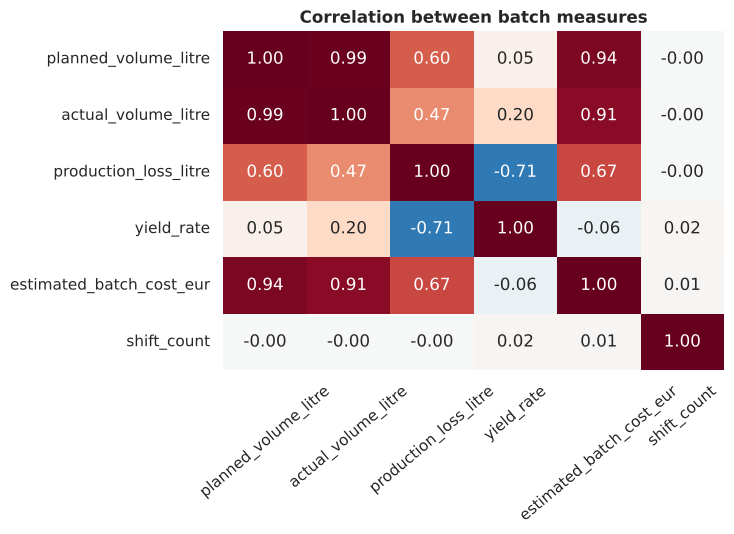

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
m = batches.groupby("month")["production_loss_litre"].sum()
ax[0].plot(m.index, m.values, color=BLUE, marker="o", ms=3)
ax[0].set(title="Production loss per month", xlabel="", ylabel="Litres lost")
y = batches.groupby("year")["yield_pct"].mean()
bars = ax[1].bar(y.index.astype(str), y.values, color=BLUE)
ax[1].bar_label(bars, fmt="%.1f%%"); ax[1].set(title="Average yield per year (2026 = Jan-Oct)", ylim=(0, 100), ylabel="Yield (%)")
save(fig, "fig03_loss_and_yield_over_time")

cols = ["planned_volume_litre", "actual_volume_litre", "production_loss_litre", "yield_rate", "estimated_batch_cost_eur", "shift_count"]
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(batches[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar=False)
ax.set_title("Correlation between batch measures"); ax.tick_params(axis="x", rotation=40)
save(fig, "fig04_batch_correlation")

**Finding.** Yearly yield is stable (88.2%, 88.1%, 89.2%, 89.0%) and monthly loss moves up and down with no trend. Planned volume, actual volume and batch cost are almost the same measurement (r = 0.94 or higher between planned volume and cost). Yield is almost unrelated to planned volume, cost and shift count (|r| of 0.06 or less), so batch size and shifts do **not** explain yield.

## 3. Quality control
### 3.1 Which products and lines get sent to "Review"?
**How to read:** each bar is the share of that group's batches with status Review. The dashed line is the overall rate. The `n=` label is the number of batches, because small groups give unstable percentages.

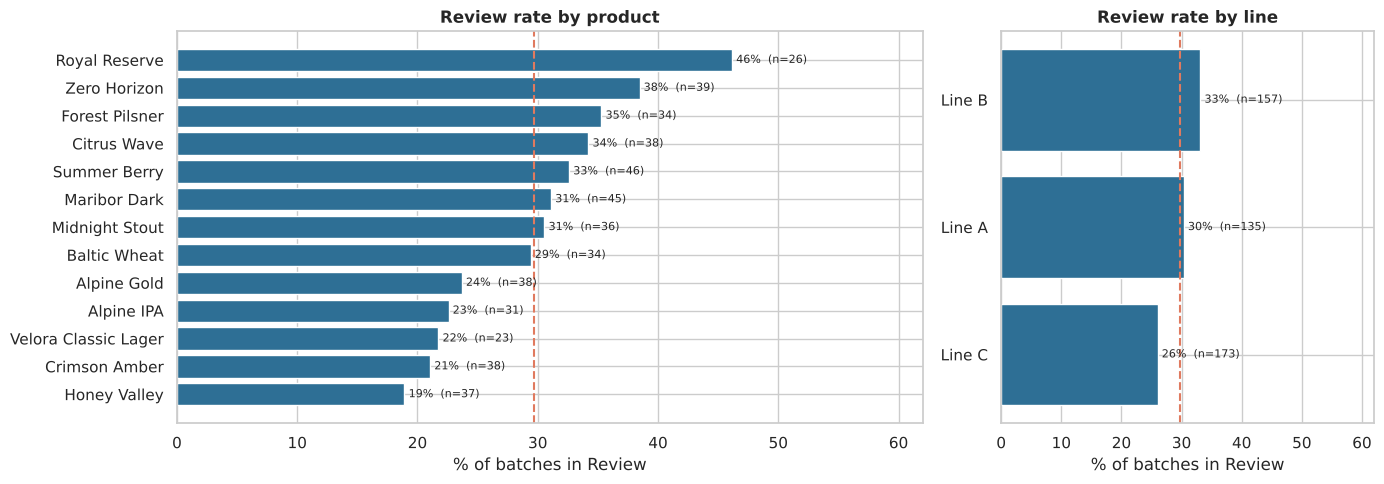

Chi-square test, review rate differs by product: p = 0.49
Chi-square test, review rate differs by line: p = 0.36
Overall Review rate: 29.7%


In [6]:
from scipy import stats
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
overall = qc["is_review"].mean() * 100
for a, col, title in [(ax[0], "product", "Review rate by product"), (ax[1], "line", "Review rate by line")]:
    r = qc.groupby(col).agg(rate=("is_review", "mean"), n=("is_review", "size")).sort_values("rate")
    bars = a.barh(r.index, r["rate"] * 100, color=BLUE)
    a.bar_label(bars, labels=[f"{v*100:.0f}%  (n={n})" for v, n in zip(r["rate"], r["n"])], padding=3, fontsize=8)
    a.axvline(overall, color=ORANGE, ls="--"); a.set(title=title, xlabel="% of batches in Review", xlim=(0, 62))
save(fig, "fig05_review_rate")
for col in ["product", "line"]:
    p = stats.chi2_contingency(pd.crosstab(qc[col], qc["quality_status"]))[1]
    print(f"Chi-square test, review rate differs by {col}: p = {p:.2f}")
print(f"Overall Review rate: {overall:.1f}%")

**Finding.** **29.7%** of batches are sent to Review. By product the rate ranges from 19% (Honey Valley) to 46% (Royal Reserve), and by line from 26% (Line C) to 33% (Line B). That looks like a real difference, but each product has only 23 to 46 batches, and a chi-square test gives p = 0.49 (products) and p = 0.36 (lines), so the differences are consistent with **chance**.

### 3.2 Do the lab measurements explain the Review decision?
**How to read:** if measurements drove the decision, the Pass and Review boxes would sit at different heights.

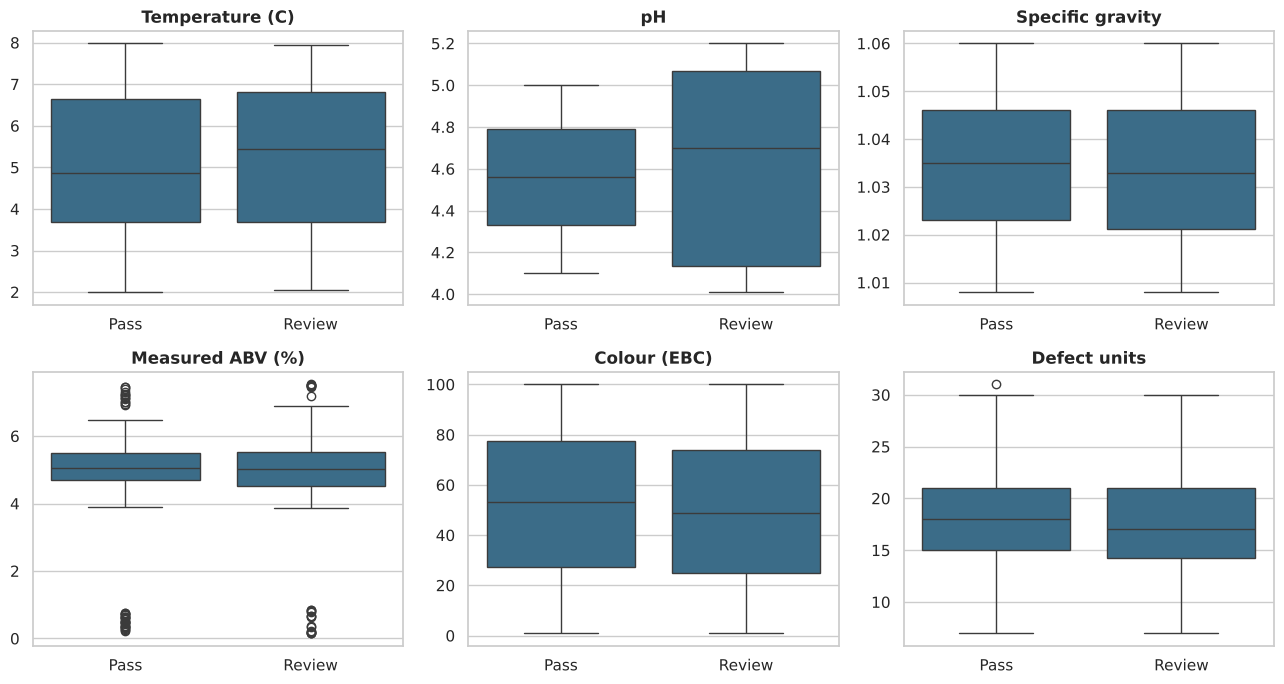

                temperature_c  ph_value  specific_gravity  \
quality_status                                              
Pass                     5.04      4.56              1.03   
Review                   5.24      4.65              1.03   

                measured_abv_percent  colour_ebc  defect_units  
quality_status                                                  
Pass                            4.89       51.93         18.19  
Review                          4.76       49.48         17.77  


In [7]:
meas = [("temperature_c", "Temperature (C)"), ("ph_value", "pH"), ("specific_gravity", "Specific gravity"),
        ("measured_abv_percent", "Measured ABV (%)"), ("colour_ebc", "Colour (EBC)"), ("defect_units", "Defect units")]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for a, (c, label) in zip(axes.ravel(), meas):
    sns.boxplot(data=qc, x="quality_status", y=c, order=["Pass", "Review"], color=BLUE, ax=a)
    a.set(title=label, xlabel="", ylabel="")
save(fig, "fig06_qc_measurements")
print(qc.groupby("quality_status")[[c for c, _ in meas]].mean().round(2))

**Finding.** Pass and Review batches have almost identical averages and heavily overlapping boxes for all six measurements. The measurements do **not** explain the Review decision. This is a property of the synthetic data, and it tells us that in the machine learning step a model predicting QC status will have **weak** results.

## 4. Sales
### 4.1 Are sales growing, and is there seasonality?
**Question:** How do monthly net sales behave across the years? **Be careful:** 2026 has only Jan-Oct, so the right-hand chart compares Jan-Oct of every year.

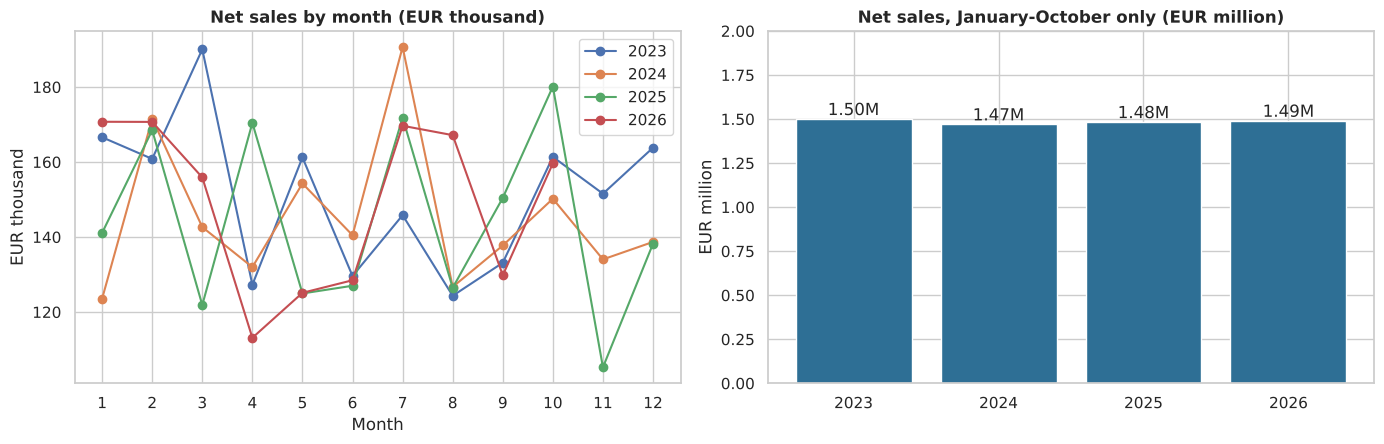

Full-year net sales (2026 is only Jan-Oct):
year
2023    1815688.0
2024    1742588.0
2025    1726271.0
2026    1490371.0

Monthly net sales range: 105,267 to 190,676


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
mon = sales.groupby(["month_no", "year"])["net_sales_eur"].sum().unstack() / 1000
for yr in mon.columns:
    ax[0].plot(mon.index, mon[yr], marker="o", label=str(yr))
ax[0].set(title="Net sales by month (EUR thousand)", xlabel="Month", ylabel="EUR thousand", xticks=range(1, 13)); ax[0].legend()
jo = sales[sales["month_no"] <= 10].groupby("year")["net_sales_eur"].sum() / 1e6
bars = ax[1].bar(jo.index.astype(str), jo.values, color=BLUE)
ax[1].bar_label(bars, fmt="%.2fM"); ax[1].set(title="Net sales, January-October only (EUR million)", ylim=(0, 2), ylabel="EUR million")
save(fig, "fig07_sales_trend")

full = sales.groupby("year")["net_sales_eur"].sum().round(0)
print("Full-year net sales (2026 is only Jan-Oct):"); print(full.to_string())
print(f"\nMonthly net sales range: {sales.groupby('month')['net_sales_eur'].sum().min():,.0f} to {sales.groupby('month')['net_sales_eur'].sum().max():,.0f}")

**Finding.** Monthly sales move between about **EUR 105k and EUR 191k** with no repeating seasonal shape: March was the best month of 2023 but among the weakest of 2025, and July was the best month of 2024. Full-year totals fall (2023 EUR 1.82M, 2024 EUR 1.74M, 2025 EUR 1.73M, 2026 EUR 1.49M), but 2026 only has ten months. **Like for like (Jan-Oct) sales are flat: EUR 1.50M, 1.47M, 1.48M, 1.49M.** Sales are not declining.

### 4.2 Which products sell most, and which earn the best margin?
**How to read:** left = total net sales, right = gross margin (gross profit / net sales).

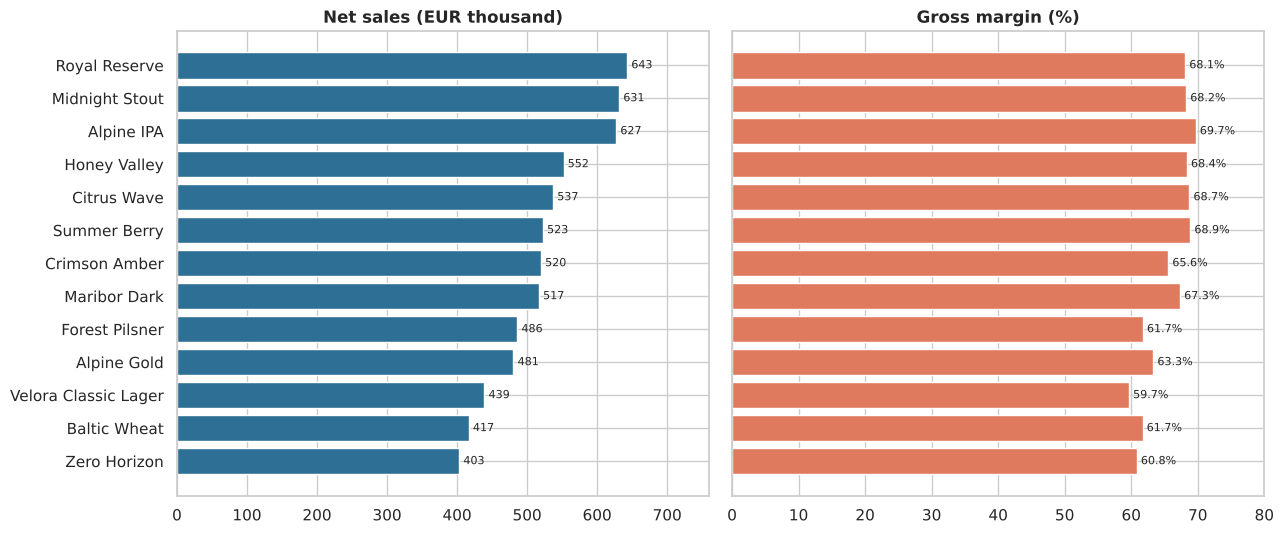

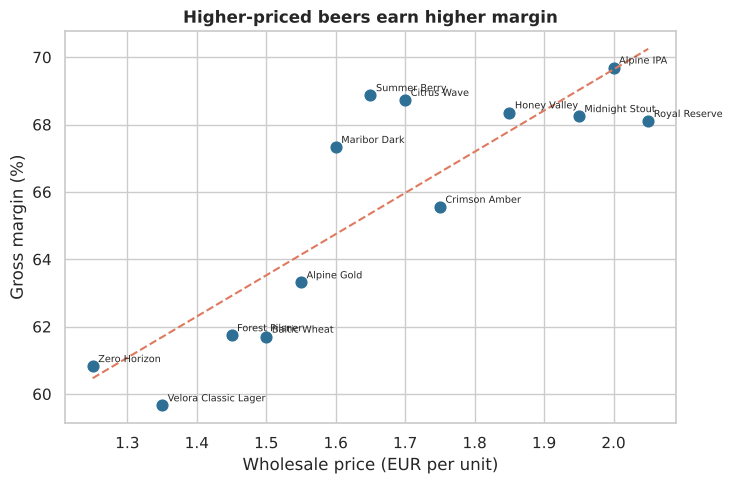

Correlation between wholesale price and margin: r = 0.85


In [9]:
p = sales.groupby("product").agg(sales=("net_sales_eur", "sum"), profit=("gross_profit_eur", "sum"))
p["margin"] = p["profit"] / p["sales"] * 100
p["price"] = p.index.map(pm.set_index("product_name")["wholesale_price_eur"])
p = p.sort_values("sales")
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
b1 = ax[0].barh(p.index, p["sales"] / 1000, color=BLUE); ax[0].bar_label(b1, fmt="%.0f", padding=3, fontsize=8)
ax[0].set(title="Net sales (EUR thousand)", xlim=(0, 760))
b2 = ax[1].barh(p.index, p["margin"], color=ORANGE); ax[1].bar_label(b2, fmt="%.1f%%", padding=3, fontsize=8)
ax[1].set(title="Gross margin (%)", xlim=(0, 80))
save(fig, "fig08_product_sales_margin")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(p["price"], p["margin"], color=BLUE, s=60)
slope, intercept = np.polyfit(p["price"], p["margin"], 1)
xs = np.linspace(p["price"].min(), p["price"].max(), 10); ax.plot(xs, slope * xs + intercept, color=ORANGE, ls="--")
for name, row in p.iterrows():
    ax.annotate(name, (row["price"], row["margin"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set(title="Higher-priced beers earn higher margin", xlabel="Wholesale price (EUR per unit)", ylabel="Gross margin (%)")
save(fig, "fig09_margin_vs_price")
print(f"Correlation between wholesale price and margin: r = {p['price'].corr(p['margin']):.2f}")

**Finding.** Royal Reserve (EUR 643k), Midnight Stout (EUR 631k) and Alpine IPA (EUR 627k) lead on sales; Zero Horizon (EUR 403k) is smallest. Margins range from 59.7% (Velora Classic Lager) to 69.7% (Alpine IPA). **Margin rises with price (r = 0.85):** the cheapest beers earn about 60% to 62%, the most expensive about 68% to 70%.

### 4.3 Where do sales come from?

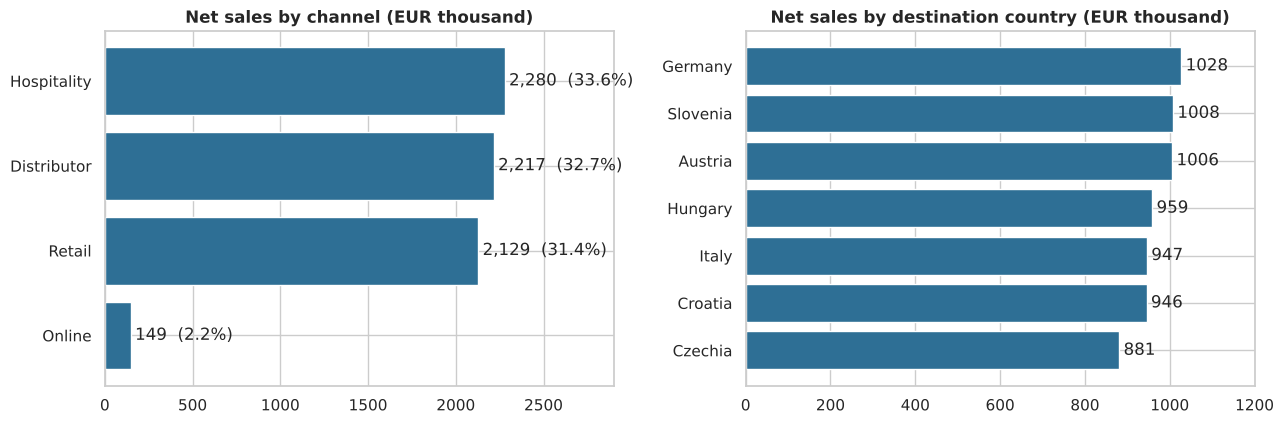

Gross margin % by channel:
sales_channel
Distributor    65.9
Hospitality    65.9
Online         66.0
Retail         66.0

Share of all orders by channel (%):
sales_channel
Distributor    25.7
Online         25.7
Hospitality    24.4
Retail         24.2

Average units per order line by channel:
                mean   max
sales_channel             
Distributor    628.0  1200
Hospitality    628.0  1200
Online          40.0    80
Retail         625.0  1200


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ch = sales.groupby("sales_channel")["net_sales_eur"].sum().sort_values() / 1000
b = ax[0].barh(ch.index, ch.values, color=BLUE)
ax[0].bar_label(b, labels=[f"{v:,.0f}  ({v / ch.sum() * 100:.1f}%)" for v in ch.values], padding=3)
ax[0].set(title="Net sales by channel (EUR thousand)", xlim=(0, 2900))
co = sales.groupby("ship_to_country")["net_sales_eur"].sum().sort_values() / 1000
b = ax[1].barh(co.index, co.values, color=BLUE); ax[1].bar_label(b, fmt="%.0f", padding=3)
ax[1].set(title="Net sales by destination country (EUR thousand)", xlim=(0, 1200))
save(fig, "fig10_channel_country")
print("Gross margin % by channel:")
print((sales.groupby("sales_channel").apply(lambda d: d["gross_profit_eur"].sum() / d["net_sales_eur"].sum() * 100, include_groups=False)).round(1).to_string())
print("\nShare of all orders by channel (%):"); print((orders["sales_channel"].value_counts(normalize=True) * 100).round(1).to_string())
print("\nAverage units per order line by channel:"); print(sales.groupby("sales_channel")["quantity_units"].agg(["mean", "max"]).round(0).to_string())

**Finding.** The **Online** channel is only **2.2%** of sales (EUR 149k), while Distributor, Hospitality and Retail bring EUR 2.1M to 2.3M each. Yet Online holds about **26% of all orders**: its order lines are tiny (average 40 units, never above 80) compared with about 628 units in the other channels. Margin is the same (66%) in every channel. Countries are evenly spread, from EUR 0.88M (Czechia) to EUR 1.03M (Germany).

### 4.4 Do discounts pay off?
**Question:** Discounts cost margin. Do they at least bring bigger orders?

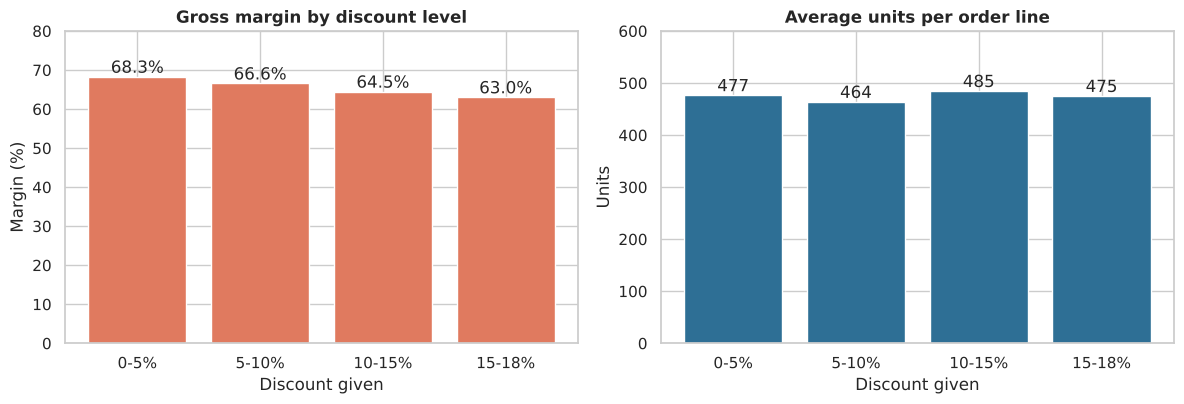

                  profit      sales  avg_qty  lines  margin
discount_band                                              
0-5%           1395588.5  2043714.3    476.7   2617    68.3
5-10%          1229272.0  1846795.3    463.9   2550    66.6
10-15%         1177493.1  1826338.8    484.8   2576    64.5
15-18%          666843.6  1058069.8    475.3   1585    63.0


In [11]:
sales["discount_band"] = pd.cut(sales["discount_rate"], [-0.001, 0.05, 0.10, 0.15, 0.18], labels=["0-5%", "5-10%", "10-15%", "15-18%"])
d = sales.groupby("discount_band", observed=True).agg(profit=("gross_profit_eur", "sum"), sales=("net_sales_eur", "sum"),
                                                      avg_qty=("quantity_units", "mean"), lines=("order_line_id", "count"))
d["margin"] = d["profit"] / d["sales"] * 100
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
b = ax[0].bar(d.index.astype(str), d["margin"], color=ORANGE); ax[0].bar_label(b, fmt="%.1f%%")
ax[0].set(title="Gross margin by discount level", xlabel="Discount given", ylabel="Margin (%)", ylim=(0, 80))
b = ax[1].bar(d.index.astype(str), d["avg_qty"], color=BLUE); ax[1].bar_label(b, fmt="%.0f")
ax[1].set(title="Average units per order line", xlabel="Discount given", ylabel="Units", ylim=(0, 600))
save(fig, "fig11_discount_effect")
print(d.round(1))

**Finding.** Margin falls steadily from **68.3%** (0-5% discount) to **63.0%** (15-18%), but the average quantity per line stays between about 460 and 485 units in every band. **Discounts cost margin and did not buy extra volume** in this data.

### 4.5 Cancellations and order sizes

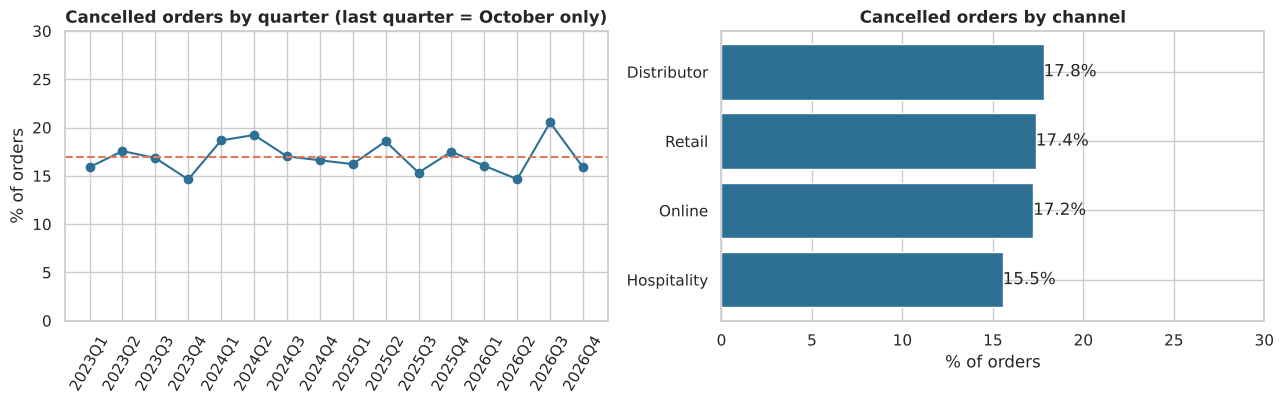

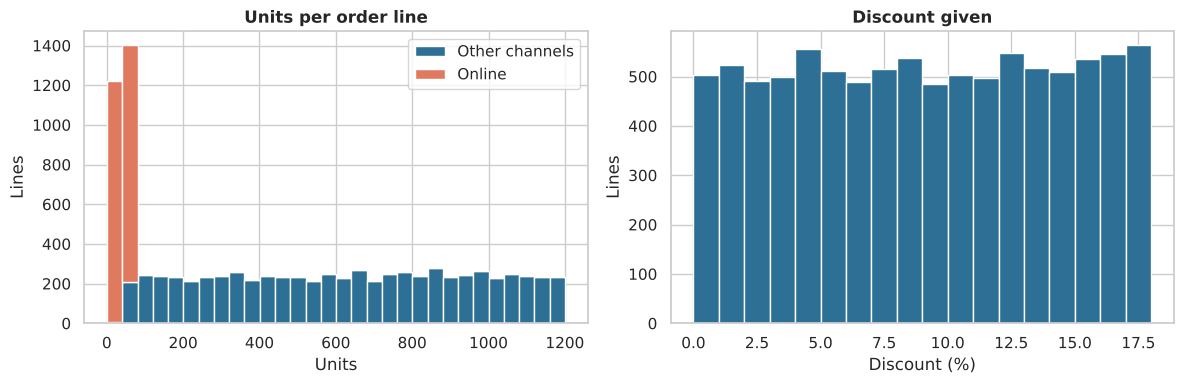

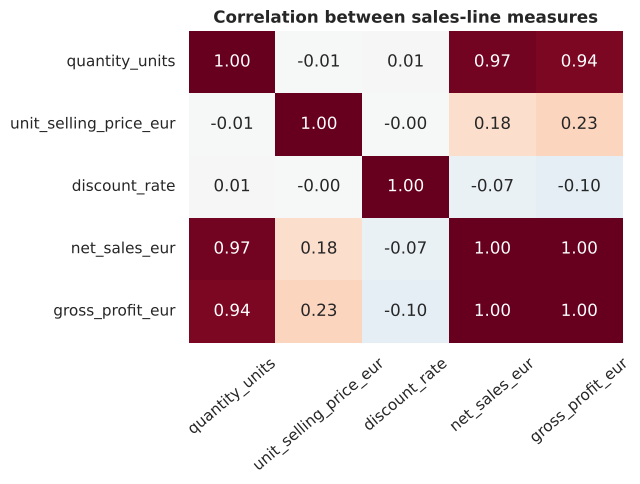

In [12]:
orders["quarter"] = orders["order_date"].dt.to_period("Q").astype(str)
orders["cancelled"] = orders["order_status"] == "Cancelled"
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
q = orders.groupby("quarter")["cancelled"].mean() * 100
ax[0].plot(q.index, q.values, marker="o", color=BLUE); ax[0].axhline(orders["cancelled"].mean() * 100, color=ORANGE, ls="--")
ax[0].set(title="Cancelled orders by quarter (last quarter = October only)", ylabel="% of orders", ylim=(0, 30)); ax[0].tick_params(axis="x", rotation=60)
c = orders.groupby("sales_channel")["cancelled"].mean().sort_values() * 100
b = ax[1].barh(c.index, c.values, color=BLUE); ax[1].bar_label(b, fmt="%.1f%%")
ax[1].set(title="Cancelled orders by channel", xlabel="% of orders", xlim=(0, 30))
save(fig, "fig12_cancellations")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
is_online = sales["sales_channel"] == "Online"
ax[0].hist([sales.loc[~is_online, "quantity_units"], sales.loc[is_online, "quantity_units"]], bins=30, stacked=True,
           color=[BLUE, ORANGE], label=["Other channels", "Online"], edgecolor="white")
ax[0].set(title="Units per order line", xlabel="Units", ylabel="Lines"); ax[0].legend()
ax[1].hist(sales["discount_rate"] * 100, bins=18, color=BLUE, edgecolor="white"); ax[1].set(title="Discount given", xlabel="Discount (%)", ylabel="Lines")
save(fig, "fig13_distributions")

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(sales[["quantity_units", "unit_selling_price_eur", "discount_rate", "net_sales_eur", "gross_profit_eur"]].corr(),
            annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar=False)
ax.set_title("Correlation between sales-line measures"); ax.tick_params(axis="x", rotation=40)
save(fig, "fig14_sales_correlation")

**Finding.** About **17%** of orders are cancelled in every quarter (roughly 15% to 21%) and in every channel (15.5% to 17.8%): no trend and no problem channel. Units per line come in two groups: Online lines are small (1 to 80 units) and all other channels spread widely up to 1,200, which is why the overall median (428) sits below the mean (475). Discounts are spread evenly between 0% and 18%. Net sales are driven almost entirely by **quantity** (r = 0.97); price has a weak link (r = 0.18) and discount a slightly negative one (r = -0.07).

## 5. Supply (procurement)
### 5.1 How often are suppliers late?
**Question:** Delay = actual delivery date minus expected delivery date (0 or less = on time).

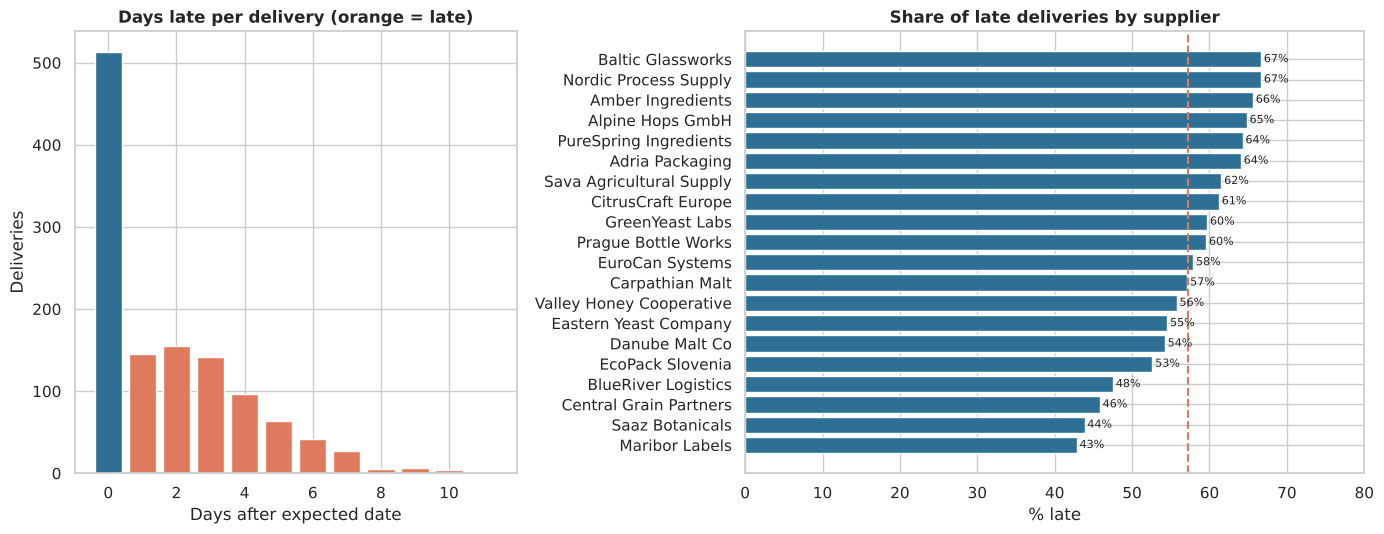

Late deliveries: 57.2% | delay median 1 d, 75th pct 3 d, max 11 d
Lead time: 2 to 25 days, mean 10.2

Share of late deliveries by year:
order_date
2023    61.8
2024    54.6
2025    56.6
2026    55.7


In [13]:
po = tables["Procurement_Orders"].copy()
po["delay"] = (po["actual_delivery_date"] - po["expected_delivery_date"]).dt.days
po["late"] = po["delay"] > 0
sup = tables["Suppliers"].set_index("supplier_id")
s = po.groupby("supplier_id").agg(late_share=("late", "mean"), orders=("po_id", "count"))
s["on_time_calc"] = (1 - s["late_share"]) * 100
s["on_time_stated"] = sup["on_time_delivery_rate"] * 100
s["name"] = sup["supplier_name"]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
vc = po["delay"].value_counts().sort_index()
ax[0].bar(vc.index, vc.values, color=[BLUE if v <= 0 else ORANGE for v in vc.index])
ax[0].set(title="Days late per delivery (orange = late)", xlabel="Days after expected date", ylabel="Deliveries")
s2 = s.sort_values("late_share")
b = ax[1].barh(s2["name"], s2["late_share"] * 100, color=BLUE); ax[1].bar_label(b, fmt="%.0f%%", padding=2, fontsize=8)
ax[1].axvline(po["late"].mean() * 100, color=ORANGE, ls="--"); ax[1].set(title="Share of late deliveries by supplier", xlabel="% late", xlim=(0, 80))
save(fig, "fig15_delivery_delays")

print(f"Late deliveries: {po['late'].mean():.1%} | delay median {po['delay'].median():.0f} d, 75th pct {po['delay'].quantile(.75):.0f} d, max {po['delay'].max()} d")
print(f"Lead time: {po['lead_time_days'].min()} to {po['lead_time_days'].max()} days, mean {po['lead_time_days'].mean():.1f}")
print("\nShare of late deliveries by year:"); print((po.groupby(po['order_date'].dt.year)["late"].mean() * 100).round(1).to_string())

**Finding.** **57.2%** of deliveries arrive late. The median delay is 1 day, the 75th percentile 3 days, and the maximum 11 days. By supplier, the late share ranges from 43% to 67%. Lead times run from 2 to 25 days (mean 10.2). The late share improved from 61.8% in 2023 to about 55% to 57% afterwards, then stayed flat.

### 5.2 Can we trust the stated on-time rate?
**How to read:** if the Suppliers sheet were right, dots would lie near the dashed diagonal.

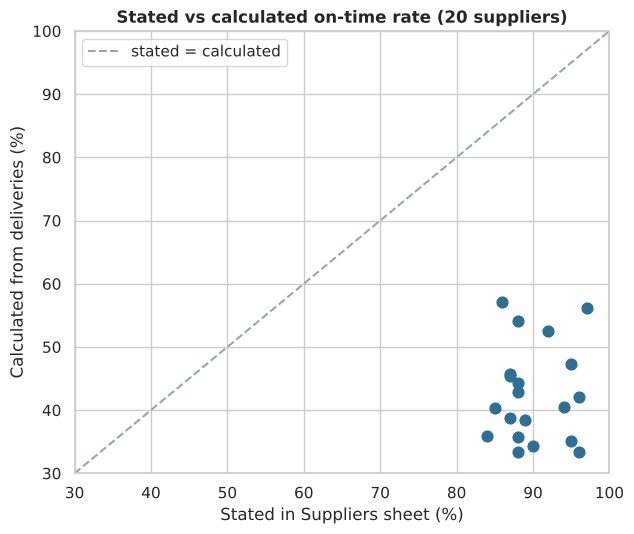

Average stated: 90% | average calculated: 43% | correlation: r = 0.05


In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(s["on_time_stated"], s["on_time_calc"], color=BLUE, s=60)
ax.plot([30, 100], [30, 100], color=GREY, ls="--", label="stated = calculated")
ax.set(title="Stated vs calculated on-time rate (20 suppliers)", xlabel="Stated in Suppliers sheet (%)",
       ylabel="Calculated from deliveries (%)", xlim=(30, 100), ylim=(30, 100)); ax.legend()
save(fig, "fig16_stated_vs_calculated")
print(f"Average stated: {s['on_time_stated'].mean():.0f}% | average calculated: {s['on_time_calc'].mean():.0f}% "
      f"| correlation: r = {s['on_time_stated'].corr(s['on_time_calc']):.2f}")

**Finding.** Stated rates average about 90%, but the rates calculated from real deliveries average about 43%, and the two have almost **no relationship** (r close to 0). A supplier claiming 97% is late as often as one claiming 84%. **The stated on-time rate cannot be used**; always use the calculated one (this confirms known data issue #1).

### 5.3 How much do we buy, and does it make sense next to sales?

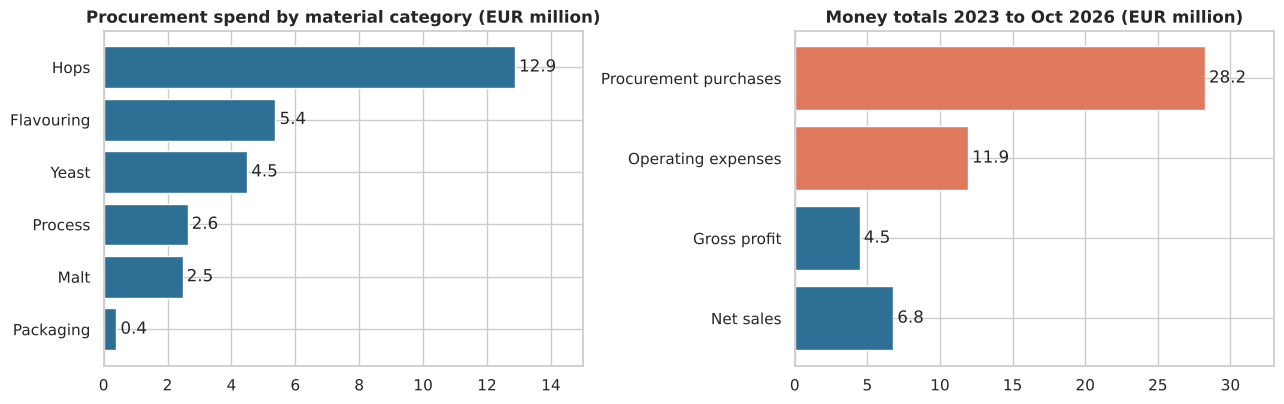

Net sales                 6.8
Gross profit              4.5
Operating expenses       11.9
Procurement purchases    28.2

Hops share of purchases: 46% | purchases / net sales = 4.2x


In [15]:
po["category"] = po["material_id"].map(tables["Raw_Materials"].set_index("material_id")["category"])
spend = po.groupby("category")["purchase_value_eur"].sum().sort_values() / 1e6
exp_total = tables["Monthly_Expenses"]["amount_eur"].sum() / 1e6
tot = pd.Series({"Net sales": sales["net_sales_eur"].sum() / 1e6, "Gross profit": sales["gross_profit_eur"].sum() / 1e6,
                 "Operating expenses": exp_total, "Procurement purchases": po["purchase_value_eur"].sum() / 1e6})
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
b = ax[0].barh(spend.index, spend.values, color=BLUE); ax[0].bar_label(b, fmt="%.1f", padding=3)
ax[0].set(title="Procurement spend by material category (EUR million)", xlim=(0, 15))
b = ax[1].barh(tot.index, tot.values, color=[BLUE, BLUE, ORANGE, ORANGE]); ax[1].bar_label(b, fmt="%.1f", padding=3)
ax[1].set(title="Money totals 2023 to Oct 2026 (EUR million)", xlim=(0, 33))
save(fig, "fig17_spend_and_totals")
print(tot.round(1).to_string()); print(f"\nHops share of purchases: {spend['Hops'] / spend.sum():.0%} | purchases / net sales = {tot['Procurement purchases'] / tot['Net sales']:.1f}x")

**Finding.** Purchases total **EUR 28.2M**, of which hops are EUR 12.9M (46%). That is **about four times net sales** (EUR 6.8M) and more than twice operating expenses (EUR 11.9M), which cannot happen in a real brewery. The procurement values are on a different scale from the sales values. Use them to compare suppliers and categories with each other, **not** to judge profitability.

## 6. Demand, expenses, maintenance and feedback
### 6.1 Demand history and promotions
**Question:** Does Demand_History show seasonality, and does it agree with the sales orders?

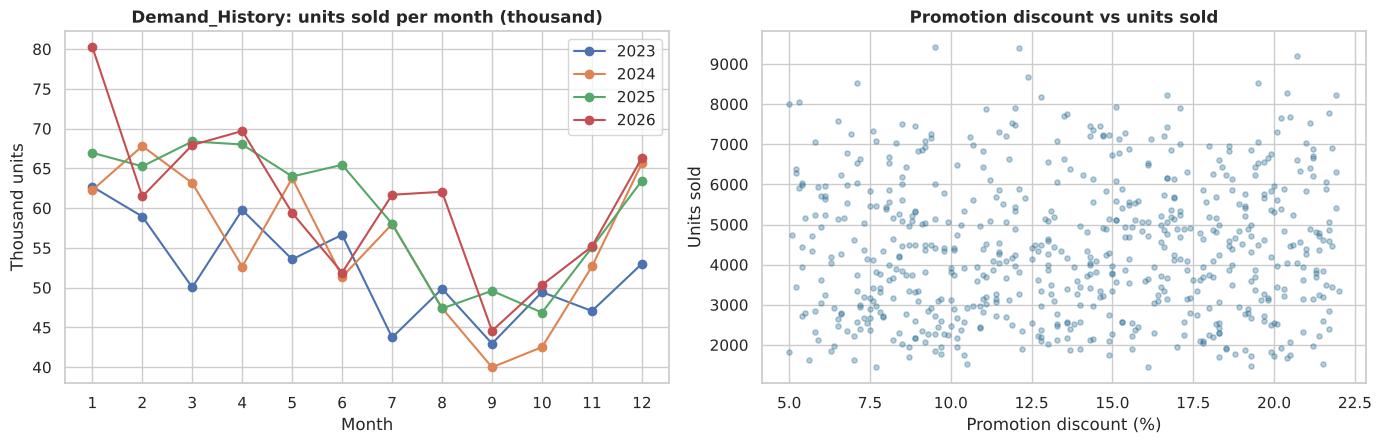

Correlation promotion vs units: r = 0.05

      Demand_History units (Jan-Oct)  Order-line units (Jan-Oct)  Demand / orders
year                                                                             
2023                          527657                      981459             0.54
2024                          548897                      960744             0.57
2025                          599911                      975247             0.62
2026                          609284                      970181             0.63


In [16]:
dh = tables["Demand_History"].copy()
dh["year"], dh["month_no"] = dh["month"].dt.year, dh["month"].dt.month
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
dm = dh.groupby(["month_no", "year"])["units_sold"].sum().unstack() / 1000
for yr in dm.columns:
    ax[0].plot(dm.index, dm[yr], marker="o", label=str(yr))
ax[0].set(title="Demand_History: units sold per month (thousand)", xlabel="Month", ylabel="Thousand units", xticks=range(1, 13)); ax[0].legend()
ax[1].scatter(dh["promotion_discount_rate"] * 100, dh["units_sold"], alpha=0.35, color=BLUE, s=14)
ax[1].set(title="Promotion discount vs units sold", xlabel="Promotion discount (%)", ylabel="Units sold")
save(fig, "fig18_demand")
print(f"Correlation promotion vs units: r = {dh['promotion_discount_rate'].corr(dh['units_sold']):.2f}\n")

# Does Demand_History agree with the order lines?  (Jan-Oct, so all years are comparable)
rec = pd.DataFrame({
    "Demand_History units (Jan-Oct)": dh[dh["month_no"] <= 10].groupby("year")["units_sold"].sum(),
    "Order-line units (Jan-Oct)": sales[sales["month_no"] <= 10].groupby("year")["quantity_units"].sum(),
})
rec["Demand / orders"] = (rec.iloc[:, 0] / rec.iloc[:, 1]).round(2)
print(rec.to_string())

**Finding.** Demand_History has a repeating yearly shape: higher from December to March and lowest from August to October. Its totals **rise** every year, while order-line sales are flat. It also reports only **54% to 63%** of the units found in the order lines (see the last table). **Demand_History does not reconcile with Sales_Order_Lines**, so treat it as a separate series when forecasting. The promotion discount has almost no link to units sold (r = 0.05), which matches the sales finding that discounts do not raise quantities.

### 6.2 Profit versus expenses

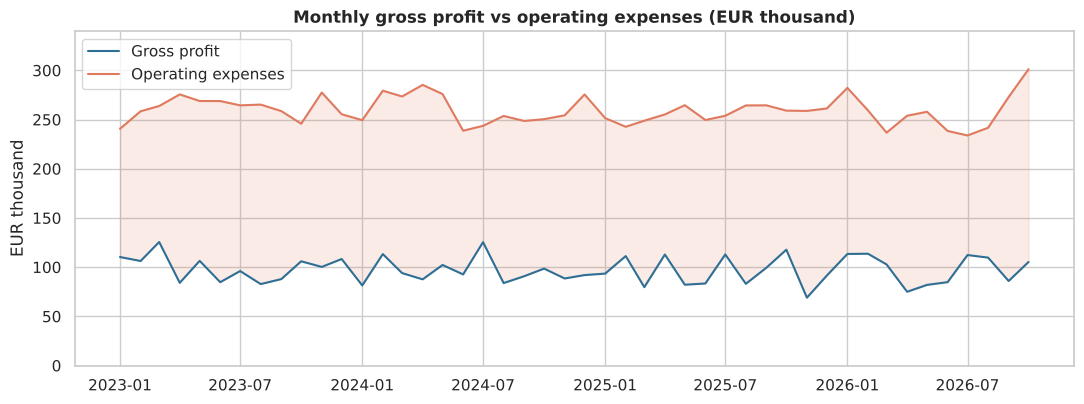

Months where expenses exceed gross profit: 46 of 46
     gross_profit  expenses
min          69.0     234.0
max         126.0     301.0


In [17]:
gp = sales.groupby("month")["gross_profit_eur"].sum()
ex = tables["Monthly_Expenses"].copy(); ex["month"] = ex["expense_month"].dt.to_period("M").dt.to_timestamp()
ex = ex.groupby("month")["amount_eur"].sum()
both = pd.concat([gp.rename("gross_profit"), ex.rename("expenses")], axis=1).dropna() / 1000
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(both.index, both["gross_profit"], color=BLUE, label="Gross profit")
ax.plot(both.index, both["expenses"], color=ORANGE, label="Operating expenses")
ax.fill_between(both.index, both["gross_profit"], both["expenses"], color=ORANGE, alpha=0.15)
ax.set(title="Monthly gross profit vs operating expenses (EUR thousand)", ylabel="EUR thousand", ylim=(0, 340)); ax.legend()
save(fig, "fig19_profit_vs_expenses")
print(f"Months where expenses exceed gross profit: {(both['expenses'] > both['gross_profit']).sum()} of {len(both)}")
print(both.describe().loc[["min", "max"]].round(0))

**Finding.** Operating expenses exceed gross profit in **every** month (46 of 46), as already seen in the SQL step. In this synthetic dataset the brewery would lose money every month, so describe this as a property of the dataset, not a business conclusion.

### 6.3 Maintenance, feedback and a customer-data check

In [18]:
mt = tables["Equipment_Maintenance"]
print("Maintenance by type:"); print(mt.groupby("maintenance_type").agg(jobs=("maintenance_id", "count"), avg_downtime_h=("downtime_hours", "mean"),
                                                                       avg_cost_eur=("maintenance_cost_eur", "mean")).round(1).to_string())
fb = tables["Customer_Feedback"]
print("\nFeedback type vs sentiment (% of each type):")
print((pd.crosstab(fb["feedback_type"], fb["sentiment_label"], normalize="index") * 100).round(0).to_string())

cust = sales.merge(tables["Customers"][["customer_id", "customer_type"]], on="customer_id")
print("\nShare of each customer type's sales by channel (%):")
print((pd.crosstab(cust["customer_type"], cust["sales_channel"], values=cust["net_sales_eur"], aggfunc="sum", normalize="index") * 100).round(0).to_string())

Maintenance by type:
                  jobs  avg_downtime_h  avg_cost_eur
maintenance_type                                    
Corrective         100             9.6        3432.8
Emergency           92             9.5        3458.1
Preventive         108            10.2        3373.3

Feedback type vs sentiment (% of each type):
sentiment_label  Negative  Neutral  Positive
feedback_type                               
Complaint            65.0      8.0      27.0
Return Request       58.0      9.0      33.0
Review               61.0      8.0      32.0

Share of each customer type's sales by channel (%):
sales_channel    Distributor  Hospitality  Online  Retail
customer_type                                            
Bar                     34.0         32.0     2.0    31.0
Hotel                   33.0         35.0     2.0    29.0
Online Customer         32.0         32.0     2.0    34.0
Restaurant              33.0         34.0     2.0    30.0
Retailer                31.0         35.0 

**Finding.**
- **Maintenance:** preventive jobs have the *longest* average downtime (10.2 h versus 9.6 h corrective and 9.5 h emergency), so preventive work does not reduce downtime in this data.
- **Feedback:** negative feedback is the majority in every feedback type (58% to 65%), including the type called "Review".
- **Customers:** every customer type shows the same pattern: about 2% of its sales through Online and 29% to 35% through each other channel. A customer called "Online Customer" buys only 2% through the Online channel, like everyone else, so `customer_type` and `sales_channel` are unrelated in this data.

## 7. Summary of the EDA

| # | Area | Main finding |
|---|---|---|
| 1 | Manufacturing | Average yield 88.6%; no difference between lines or batch status; 11.3% of planned volume lost |
| 2 | Manufacturing | Every product is within 1.4 points of its yield target; yield is unrelated to batch size, cost or shifts |
| 3 | Quality | 29.7% of batches go to Review; product and line differences are consistent with chance (p = 0.49 and 0.36) |
| 4 | Quality | Lab measurements do not explain Review, so expect weak QC prediction in Step 8 |
| 5 | Sales | Jan-Oct sales are flat across all four years (EUR 1.47M to 1.50M); no stable seasonality |
| 6 | Sales | Margin rises with price (r = 0.85); the cheapest beers earn about 60%, the dearest about 69% |
| 7 | Sales | Discounts cut margin from 68.3% to 63.0% without raising quantity per order |
| 8 | Sales | Online is 26% of orders but only 2.2% of sales (tiny orders); about 17% of orders are cancelled everywhere |
| 9 | Supply | 57% of deliveries are late; the stated supplier on-time rate cannot be trusted |

### New data issues found in this step (added to `docs/data_model.md`)
- **Procurement purchases (EUR 28.2M) are four times net sales (EUR 6.8M).**
- **Demand_History does not reconcile with Sales_Order_Lines** (54% to 63% of the units, and rising while orders are flat).
- **`customer_type` and `sales_channel` are unrelated** (an "Online Customer" buys only 2% through the Online channel, like every other type).

### Handing over to Step 6 (data cleaning)
Rebuild `first_order_date` and `season`; use the calculated supplier on-time rate; exclude cancelled orders in one reusable function; keep 2026 flagged as a partial year.